In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

df = pd.read_csv("data/AmesHousing.csv", sep="	")

## C1. Feature Pairs Selection

1. **Gr Liv Area vs. SalePrice:** Above-ground living area.
2. **Overall Qual vs. SalePrice:** Overall material and finish quality of the house (rated from 1 to 10).

Pearson Correlation (Gr Liv Area vs SalePrice): 0.707
Pearson Correlation (Overall Qual vs SalePrice): 0.799


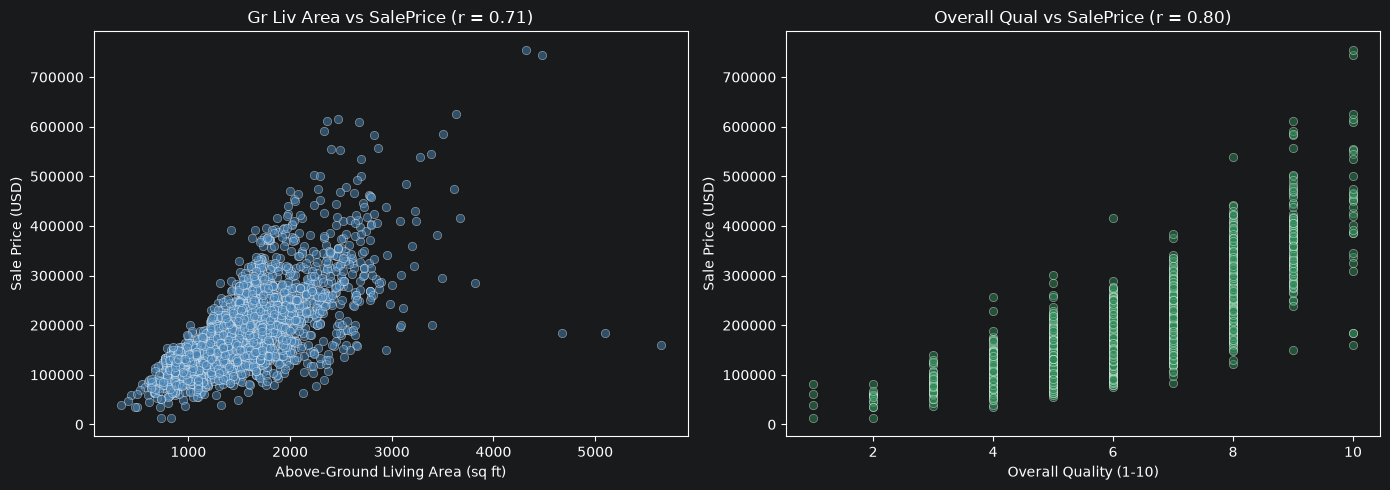

In [33]:
df_clean = df.dropna(subset=["Gr Liv Area", "Overall Qual", "SalePrice"]).copy()

corr_1 = df_clean["Gr Liv Area"].corr(df_clean["SalePrice"])
corr_2 = df_clean["Overall Qual"].corr(df_clean["SalePrice"])

print(f"Pearson Correlation (Gr Liv Area vs SalePrice): {corr_1:.3f}")
print(f"Pearson Correlation (Overall Qual vs SalePrice): {corr_2:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df_clean, x="Gr Liv Area", y="SalePrice", alpha=0.5, color="steelblue", ax=axes[0])
axes[0].set_title(f"Gr Liv Area vs SalePrice (r = {corr_1:.2f})")
axes[0].set_xlabel("Above-Ground Living Area (sq ft)")
axes[0].set_ylabel("Sale Price (USD)")

sns.scatterplot(data=df_clean, x="Overall Qual", y="SalePrice", alpha=0.5, color="seagreen", ax=axes[1])
axes[1].set_title(f"Overall Qual vs SalePrice (r = {corr_2:.2f})")
axes[1].set_xlabel("Overall Quality (1-10)")
axes[1].set_ylabel("Sale Price (USD)")

plt.tight_layout()
plt.show()

## C2. Linear Regression: Model 1 (Gr Liv Area)

Train a simple linear regression model of the form $y = \beta_0 + \beta_1 x$, where $y$ is `SalePrice` and $x$ is `Gr Liv Area`.

Model 1 Equation: SalePrice = 13289.63 + 111.69 * Gr Liv Area


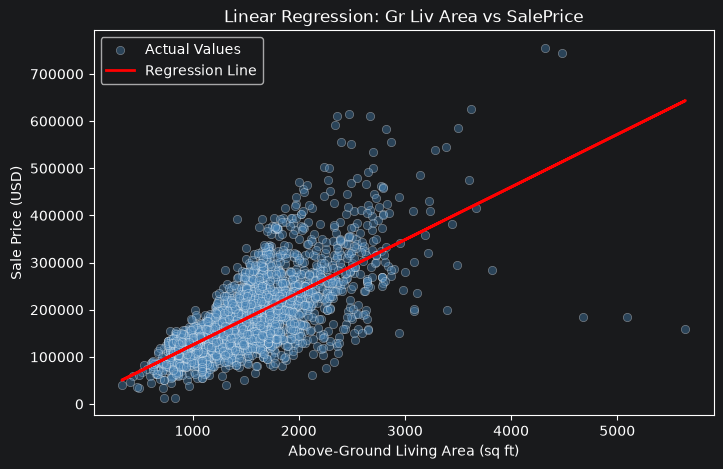

In [34]:
X1 = df_clean[["Gr Liv Area"]]
y = df_clean["SalePrice"]

model1 = LinearRegression()
model1.fit(X1, y)

slope1 = model1.coef_[0]
intercept1 = model1.intercept_

print(f"Model 1 Equation: SalePrice = {intercept1:.2f} + {slope1:.2f} * Gr Liv Area")

y_pred1 = model1.predict(X1)

plt.figure(figsize=(8, 5))
sns.scatterplot(x=df_clean["Gr Liv Area"], y=y, alpha=0.4, color="steelblue", label="Actual Values")
plt.plot(df_clean["Gr Liv Area"], y_pred1, color="red", linewidth=2, label="Regression Line")
plt.title("Linear Regression: Gr Liv Area vs SalePrice")
plt.xlabel("Above-Ground Living Area (sq ft)")
plt.ylabel("Sale Price (USD)")
plt.legend()
plt.show()

## C3. Linear Regression: Model 2 (Overall Qual)

Train a simple linear regression model of the form $y = \beta_0 + \beta_1 x$, where $y$ is `SalePrice` and $x$ is `Overall Qual` (overall material and finish quality rating on a scale from 1 to 10).

Model 2 Equation: SalePrice = -95003.55 + 45251.03 * Overall Qual


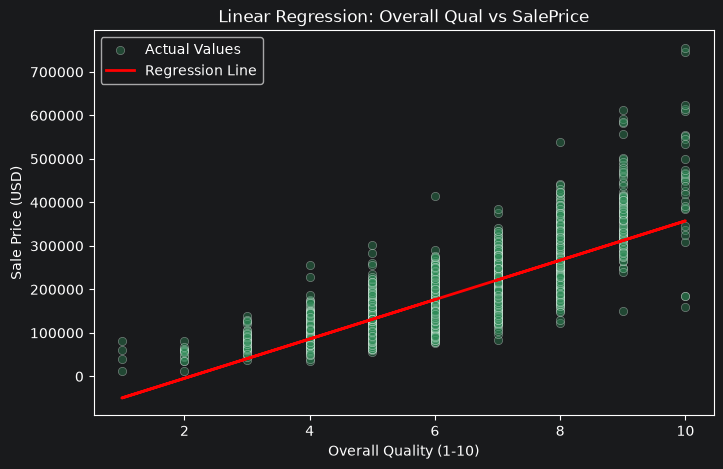

In [35]:
X2 = df_clean[["Overall Qual"]]
y = df_clean["SalePrice"]

model2 = LinearRegression()
model2.fit(X2, y)

slope2 = model2.coef_[0]
intercept2 = model2.intercept_

print(f"Model 2 Equation: SalePrice = {intercept2:.2f} + {slope2:.2f} * Overall Qual")

y_pred2 = model2.predict(X2)

plt.figure(figsize=(8, 5))
sns.scatterplot(x=df_clean["Overall Qual"], y=y, alpha=0.4, color="seagreen", label="Actual Values")
plt.plot(df_clean["Overall Qual"], y_pred2, color="red", linewidth=2, label="Regression Line")
plt.title("Linear Regression: Overall Qual vs SalePrice")
plt.xlabel("Overall Quality (1-10)")
plt.ylabel("Sale Price (USD)")
plt.legend()
plt.show()

## C4. Predictions, Evaluation & Interpretation


In [38]:
sample_real = df_clean.sample(3, random_state=42)

print("⎯⎯⎯ Predictions for EXISTING homes in the dataset ⎯⎯⎯")
for idx, row in sample_real.iterrows():
    real_price = row['SalePrice']

    area1 = row['Gr Liv Area']
    pred1 = model1.predict(pd.DataFrame([[area1]], columns=["Gr Liv Area"]))[0]

    qual2 = row['Overall Qual']
    pred2 = model2.predict(pd.DataFrame([[qual2]], columns=["Overall Qual"]))[0]

    print(f"House ID {row['PID']}: Actual Price = ${real_price:,.2f}")
    print(f"  Model 1 (Gr Liv Area: {area1} sq ft) predicts: ${pred1:,.2f} (Error: ${abs(real_price - pred1):,.2f})")
    print(f"  Model 2 (Overall Qual: {qual2}/10) predicts: ${pred2:,.2f} (Error: ${abs(real_price - pred2):,.2f})")
    print()

print("⎯⎯⎯ Predictions for HYPOTHETICAL values ⎯⎯⎯")
hypothetical_grliv_values = [1000, 2000, 3000]
for val in hypothetical_grliv_values:
    pred_hypothetical1 = model1.predict(pd.DataFrame([[val]], columns=["Gr Liv Area"]))[0]
    print(f"If a house has a living area (Gr Liv Area) of {val} sq ft, Model 1 predicts a price of: ${pred_hypothetical1:,.2f}")

print()
hypothetical_qual_values = [4, 8, 9]
for val in hypothetical_qual_values:
    pred_hypothetical2 = model2.predict(pd.DataFrame([[val]], columns=["Overall Qual"]))[0]
    print(f"If a house has an overall quality (Overall Qual) of {val}/10, Model 2 predicts a price of: ${pred_hypothetical2:,.2f}")

mae1 = mean_absolute_error(y, y_pred1)
rmse1 = root_mean_squared_error(y, y_pred1)

mae2 = mean_absolute_error(y, y_pred2)
rmse2 = root_mean_squared_error(y, y_pred2)

print()
print("⎯⎯⎯ Global Error Evaluation ⎯⎯⎯")
print(f"Model 1 (Gr Liv Area) -> MAE: ${mae1:,.2f} | RMSE: ${rmse1:,.2f}")
print(f"Model 2 (Overall Qual) -> MAE: ${mae2:,.2f} | RMSE: ${rmse2:,.2f}")

⎯⎯⎯ Predictions for EXISTING homes in the dataset ⎯⎯⎯
House ID 903427090: Actual Price = $161,000.00
  Model 1 (Gr Liv Area: 1666 sq ft) predicts: $199,371.84 (Error: $38,371.84)
  Model 2 (Overall Qual: 8/10) predicts: $267,004.67 (Error: $106,004.67)

House ID 527450460: Actual Price = $116,000.00
  Model 1 (Gr Liv Area: 1030 sq ft) predicts: $128,334.46 (Error: $12,334.46)
  Model 2 (Overall Qual: 6/10) predicts: $176,502.62 (Error: $60,502.62)

House ID 908128100: Actual Price = $196,500.00
  Model 1 (Gr Liv Area: 1724 sq ft) predicts: $205,850.09 (Error: $9,350.09)
  Model 2 (Overall Qual: 7/10) predicts: $221,753.65 (Error: $25,253.65)

⎯⎯⎯ Predictions for HYPOTHETICAL values ⎯⎯⎯
If a house has a living area (Gr Liv Area) of 1000 sq ft, Model 1 predicts a price of: $124,983.64
If a house has a living area (Gr Liv Area) of 2000 sq ft, Model 1 predicts a price of: $236,677.64
If a house has a living area (Gr Liv Area) of 3000 sq ft, Model 1 predicts a price of: $348,371.64

If a ho